In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

RANDOM_STATE = 42

In [7]:
iris = load_iris()

X = iris.data
y = iris.target
class_names = iris.target_names

print("Number of flowers:", len(X))
print("Number of features:", X.shape[1])
print("Class names:", class_names)
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Number of flowers: 150
Number of features: 4
Class names: ['setosa' 'versicolor' 'virginica']
Shape of X: (150, 4)
Shape of y: (150,)


In [8]:
#before it data was [5.1,3.5,1.4,0.2]... 

flowers = pd.DataFrame(X, columns=iris.feature_names)
flowers["species"] = class_names[y]
display(flowers.head(10)) #show first 10 rows of the dataset


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


In [9]:
class_counts = flowers["species"].value_counts()
print(class_counts)

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


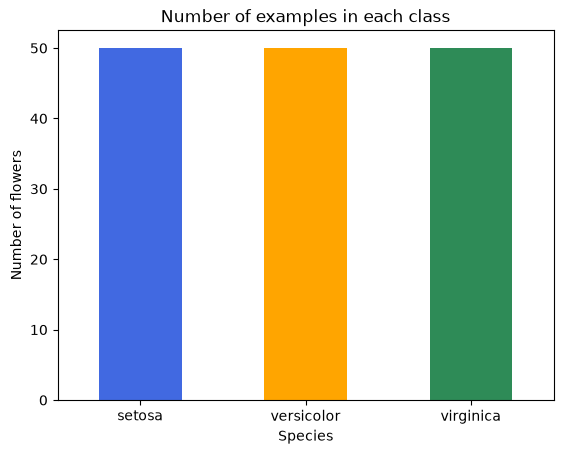

In [10]:
class_counts.plot(
    kind="bar",
    color=["royalblue", "orange", "seagreen"]
)

plt.title("Number of examples in each class")
plt.xlabel("Species")
plt.ylabel("Number of flowers")
plt.xticks(rotation=0)
plt.show()

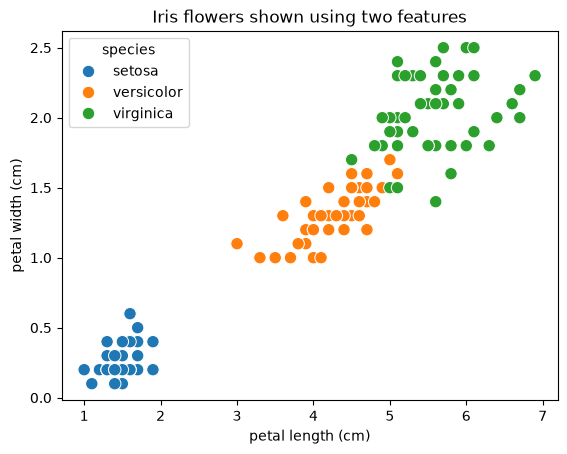

In [11]:
sns.scatterplot(
 data=flowers,
 x="petal length (cm)",
 y="petal width (cm)",
 hue="species",
 s=80,
)
plt.title("Iris flowers shown using two features")
plt.show()

In [ ]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20, #20% of the data will be used for testing
    random_state=RANDOM_STATE,  #random state for reproducibility
    stratify=y, #save the proportion of classes in the training and testing sets
)

In [13]:
print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))
print("Training class counts:", np.bincount(y_train))
print("Testing class counts:", np.bincount(y_test))

Training examples: 120
Testing examples: 30
Training class counts: [40 40 40]
Testing class counts: [10 10 10]


In [14]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [15]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("First original training example:", X_train[0])
print("First scaled training example:", X_train_scaled[0].round(3))

First original training example: [4.4 2.9 1.4 0.2]
First scaled training example: [-1.722 -0.332 -1.346 -1.323]


In [16]:
knn_model = KNeighborsClassifier(n_neighbors=3)
knn_model.fit(X_train_scaled, y_train) # store the trained model in knn_model
print("The model has been trained.")

The model has been trained.


In [17]:
y_pred = knn_model.predict(X_test_scaled)
comparison = pd.DataFrame({
 "Correct species": class_names[y_test],
 "Predicted species": class_names[y_pred],
 "Correct?": y_test == y_pred,
})
display(comparison)


,Correct species,Predicted species,Correct?
0,setosa,setosa,True
1,virginica,virginica,True
2,versicolor,versicolor,True
3,versicolor,versicolor,True
4,setosa,setosa,True
5,versicolor,versicolor,True
6,setosa,setosa,True
7,setosa,setosa,True
8,virginica,virginica,True
9,versicolor,versicolor,True


In [18]:
flower_number = 0

one_flower = X_test_scaled[flower_number].reshape(1, -1)

one_prediction = knn_model.predict(one_flower)[0]

print("Original measurements:", X_test[flower_number])
print("Correct species:", class_names[y_test[flower_number]])
print("Predicted species:", class_names[one_prediction])

Original measurements: [4.4 3.  1.3 0.2]
Correct species: setosa
Predicted species: setosa


In [19]:
accuracy = accuracy_score(y_test, y_pred)

correct_predictions = np.sum(y_test == y_pred)

print(
    "Correct predictions:",
    correct_predictions,
    "out of",
    len(y_test)
)

print("Accuracy:", round(accuracy, 3))
print("Accuracy percentage:", round(accuracy * 100, 1), "%")

Correct predictions: 28 out of 30
Accuracy: 0.933
Accuracy percentage: 93.3 %


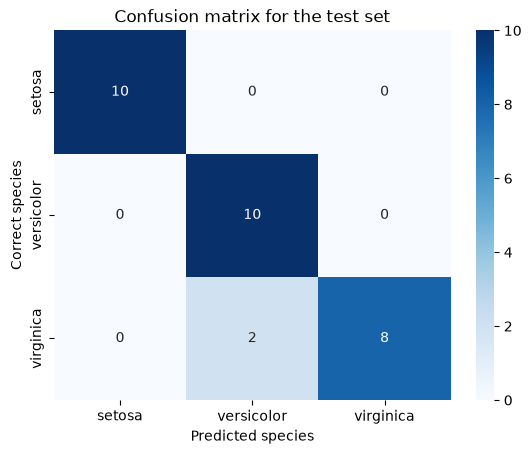

In [20]:
matrix = confusion_matrix(y_test, y_pred)

sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
)

plt.xlabel("Predicted species")
plt.ylabel("Correct species")
plt.title("Confusion matrix for the test set")
plt.show()

In [ ]:
experiment_results = []

for k in [1, 3, 5, 7, 9]:
    experiment_model = KNeighborsClassifier(n_neighbors=k)

    experiment_model.fit(X_train_scaled, y_train)

    experiment_predictions = experiment_model.predict(X_test_scaled)
    #experiment_accuracy = None
    experiment_accuracy = accuracy_score(
        y_test,
        experiment_predictions
    )

    experiment_results.append({
        "k": k,
        "accuracy": experiment_accuracy,
    })

experiment_table = pd.DataFrame(experiment_results)

display(experiment_table)

,k,accuracy
0,1,0.966667
1,3,0.933333
2,5,0.933333
3,7,0.966667
4,9,0.966667


In [22]:
neural_network = MLPClassifier(
 hidden_layer_sizes=(8,),
 max_iter=2000,
 random_state=RANDOM_STATE,
)
neural_network.fit(X_train_scaled, y_train)
neural_predictions = neural_network.predict(X_test_scaled)
neural_accuracy = accuracy_score(y_test, neural_predictions)
model_comparison = pd.DataFrame({
 "Model": ["k-NN (k=3)", "Small neural network"],
 "Test accuracy": [accuracy, neural_accuracy],
})
display(model_comparison.round(3))

,Model,Test accuracy
0,k-NN (k=3),0.933
1,Small neural network,0.933
